# 00 — Data & Model (MNIST + SmallCNN)

Download MNIST, inspect the dataset, define a small CNN, and verify every dimension of the forward pass before any training happens.

**Run all cells top-to-bottom.**

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook --notebook-dir=image_nets/notebooks`

**What we do:** Imports, path setup, seeds, and `FORCE_CPU` flag.
**Why:** All configuration in one cell — change `FORCE_CPU = True` to run without GPU end-to-end.
**What you should see:** No output.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))   # image_nets/

import torch
import numpy as np
import matplotlib.pyplot as plt
import json
from torchvision import datasets, transforms

from tools.nets.cnn import SmallCNN

FORCE_CPU  = False
SEED       = 42
N_CLASSES  = 10
VAL_FRAC   = 0.1           # 10% of 60k train → 6000 val samples
BATCH_SIZE = 128

torch.manual_seed(SEED)
np.random.seed(SEED)

**What we do:** Detect the GPU and set the compute device.
**Why:** Record device in `env.json` so later notebooks pick it up.
**What you should see:** `cuda` if the GPU is available, else `cpu`.

In [2]:
NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"
DATA_DIR      = ARTIFACTS_DIR / "mnist_data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

if FORCE_CPU:
    device = torch.device("cpu")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb  = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"GPU : {gpu_name}  ({vram_gb:.1f} GB)")
else:
    device = torch.device("cpu")

print(f"device : {device}")
env = {"device": str(device)}
with open(ARTIFACTS_DIR / "env.json", "w") as f:
    json.dump(env, f)
print("PASS: device detected")

GPU : NVIDIA GeForce RTX 2050  (4.3 GB)
device : cuda
PASS: device detected


**What we do:** Download MNIST (if not cached) and build the full train + test datasets.
**Why:** We use the canonical MNIST split: 60k train (→ 54k fit / 6k val) and 10k test (touched only in notebook 01's final eval).
**What you should see:** Download progress (first run only), then dataset sizes.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),   # MNIST channel mean / std
])

train_full = datasets.MNIST(DATA_DIR, train=True,  download=True, transform=transform)
test_set   = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

n_val   = int(len(train_full) * VAL_FRAC)
n_train = len(train_full) - n_val

rng        = torch.Generator().manual_seed(SEED)
train_set, val_set = torch.utils.data.random_split(
    train_full, [n_train, n_val], generator=rng
)

print(f"train  : {len(train_set):>6,} samples")
print(f"val    : {len(val_set):>6,} samples")
print(f"test   : {len(test_set):>6,} samples")
print(f"classes: {N_CLASSES}")

assert len(train_set) == 54000, "FAIL: train size"
assert len(val_set)   ==  6000, "FAIL: val size"
assert len(test_set)  == 10000, "FAIL: test size"
print("PASS: dataset sizes correct")

train  : 54,000 samples
val    :  6,000 samples
test   : 10,000 samples
classes: 10
PASS: dataset sizes correct


**What we do:** Plot 25 random training images in a 5×5 grid.
**Why:** Always look at your data first — confirms the transform is correct and gives intuition for what the model must learn.
**What you should see:** 25 handwritten digits, each labelled with its class.

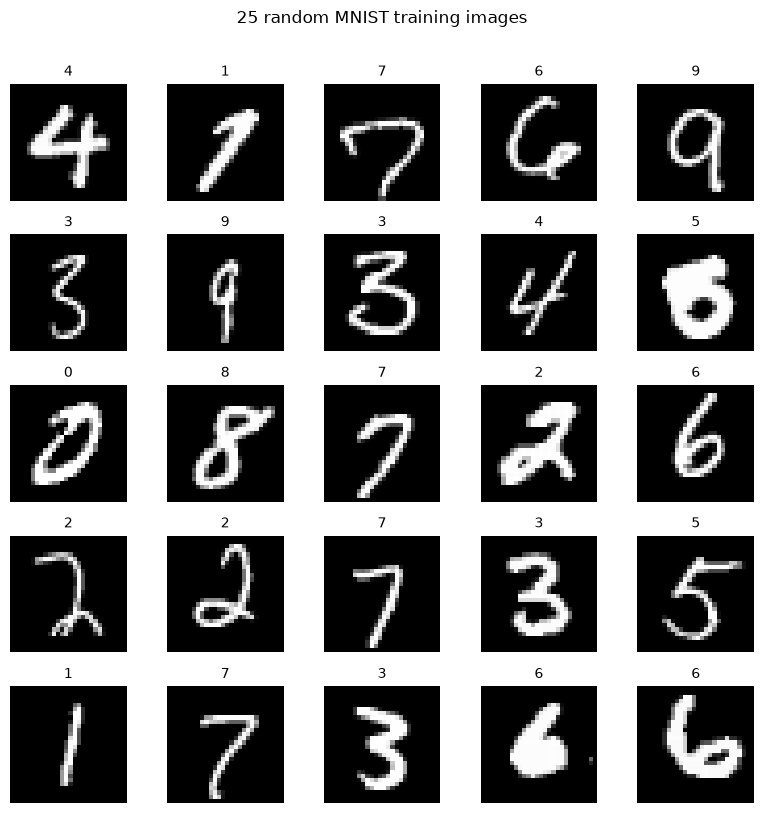

In [4]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
indices   = torch.randint(len(train_set), (25,), generator=torch.Generator().manual_seed(SEED))

for ax, idx in zip(axes.flat, indices):
    img, label = train_set[int(idx)]
    ax.imshow(img[0].numpy(), cmap="gray")
    ax.set_title(str(label), fontsize=10)
    ax.axis("off")

fig.suptitle("25 random MNIST training images", y=1.01)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "mnist_samples.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Plot the class distribution of the training set.
**Why:** MNIST is nearly balanced; if the bars were very uneven we'd need class-weighted loss.
**What you should see:** 10 roughly equal bars, each near 5,400.

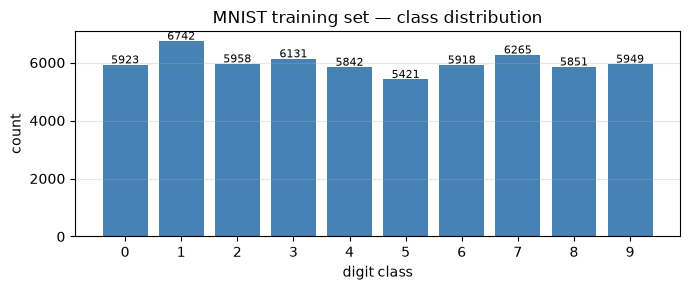

Class balance CV = 0.054  (MNIST ranges ~5400–6700; CV < 0.10 is fine)
PASS: dataset balance acceptable


In [5]:
labels_all = [train_full[i][1] for i in range(len(train_full))]
counts     = np.bincount(labels_all, minlength=N_CLASSES)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(N_CLASSES), counts, color="steelblue")
ax.set_xticks(range(N_CLASSES))
ax.set_xlabel("digit class"); ax.set_ylabel("count")
ax.set_title("MNIST training set — class distribution")
ax.grid(axis="y", alpha=0.3)
for i, c in enumerate(counts):
    ax.text(i, c + 50, str(c), ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "class_distribution.png", dpi=100, bbox_inches="tight")
plt.show()

cv = counts.std() / counts.mean()
print(f"Class balance CV = {cv:.3f}  (MNIST ranges ~5400–6700; CV < 0.10 is fine)")
assert cv < 0.10, f"FAIL: dataset badly unbalanced (CV={cv:.3f})"
print("PASS: dataset balance acceptable")

**What we do:** Instantiate `SmallCNN` and print its architecture.
**Why:** Confirms the layer shapes before any training — catch wrong sizes early.
**What you should see:** Module tree with Conv2d / ReLU / MaxPool / Linear layers.

In [6]:
model = SmallCNN(n_classes=N_CLASSES).to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal parameters: {n_params:,}")

SmallCNN(
  (conv1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Total parameters: 206,922


**What we do:** Run one batch through the network and assert the output shape.
**Why:** A shape error here is trivial to fix; the same error during training produces a confusing loss-explosion.
**What you should see:** `output shape: torch.Size([4, 10])` and PASS.

In [7]:
dummy = torch.randn(4, 1, 28, 28).to(device)
model.eval()
with torch.no_grad():
    out = model(dummy)

print(f"input  shape : {dummy.shape}")
print(f"output shape : {out.shape}")

assert out.shape == (4, N_CLASSES), f"FAIL: {out.shape}"
print("PASS: forward pass shape correct")

input  shape : torch.Size([4, 1, 28, 28])
output shape : torch.Size([4, 10])
PASS: forward pass shape correct


**What we do:** Verify that feature-map spatial sizes halve at each MaxPool.
**Why:** The FC layer expects exactly 32 × 7 × 7 = 1568 inputs. If padding or kernel size is wrong the flatten dimension mismatches.
**What you should see:** conv1→(16,14,14)  conv2→(32,7,7)  and PASS.

In [8]:
store = {}
h1 = model.conv1.register_forward_hook(lambda m,i,o: store.update({"c1": o.shape}))
h2 = model.conv2.register_forward_hook(lambda m,i,o: store.update({"c2": o.shape}))

with torch.no_grad():
    model(dummy)

h1.remove(); h2.remove()

print(f"after conv1 : {store['c1']}   (batch, 16 ch, 14×14)")
print(f"after conv2 : {store['c2']}   (batch, 32 ch,  7×7)")

assert store["c1"][2:] == (14, 14), f"FAIL: conv1 spatial {store['c1'][2:]}"
assert store["c2"][2:] == ( 7,  7), f"FAIL: conv2 spatial {store['c2'][2:]}"
print("PASS: spatial sizes correct")

after conv1 : torch.Size([4, 16, 14, 14])   (batch, 16 ch, 14×14)
after conv2 : torch.Size([4, 32, 7, 7])   (batch, 32 ch,  7×7)
PASS: spatial sizes correct


**What we do:** Save dataset config to `artifacts/config.json` for downstream notebooks.
**Why:** Notebooks share state only through `artifacts/` — no global variables across files.
**What you should see:** Config printed, PASS.

In [9]:
config = {
    "n_classes"  : N_CLASSES,
    "val_frac"   : VAL_FRAC,
    "batch_size" : BATCH_SIZE,
    "seed"       : SEED,
    "input_shape": [1, 28, 28],
    "n_params"   : n_params,
}
with open(ARTIFACTS_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print(json.dumps(config, indent=2))
print("\nPASS: config saved")

{
  "n_classes": 10,
  "val_frac": 0.1,
  "batch_size": 128,
  "seed": 42,
  "input_shape": [
    1,
    28,
    28
  ],
  "n_params": 206922
}

PASS: config saved
